# TP Final — Inteligencia Artificial 2026 (UNAB)
## Etapa 5: Cierre, evaluación final en Test y análisis ético

**Plan de la etapa**
1. **Configuración y datos:** misma partición por bloques de la Etapa 1. Acá se arman por primera vez las ventanas de Test.
2. **Consigna 4.5.2, evaluación final en Test:** reentrenamos el ganador de la Etapa 3 con su misma configuración y las 5 semillas, verificamos que reproduce su accuracy en Dev y lo evaluamos en Test **una única vez**.
3. **Consigna 4.5.1, tabla comparativa:** todos los modelos del trabajo con arquitectura, parámetros, Dev, Test y tiempo. Va después de la sección 2 porque necesita el resultado en Test.
4. **Consigna 4.5.3, análisis ético y de sesgos:** sesgos del texto y desempeño por subgrupos en Test.
5. **Consigna 4.5.4, conclusiones.**

**Decisiones de diseño**
1. **Solo el ganador se evalúa en Test.** La consigna 4.5.2 pide evaluar *el mejor modelo* por primera y única vez. Los demás modelos de la tabla llevan solo su accuracy en Dev, leída de los resultados guardados de cada etapa.
2. **Reentrenar en lugar de guardar pesos.** Con las semillas fijas, el entrenamiento da exactamente los mismos números; lo verificamos contra el Dev de la Etapa 3 antes de mirar Test.
3. **Resultado en Test con 5 semillas:** media ± desvío, igual que en Dev, para que la comparación sea justa.

---
# 1. Configuración y datos

In [1]:
# ==============================================================================
# 1.1 CONFIGURACIÓN DEL ENTORNO
# ==============================================================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import re
import json
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

SEED = 42
SEEDS = [42, 123, 456, 789, 2026]
np.random.seed(SEED)

print(f"TensorFlow {tf.__version__} | Keras {keras.__version__}")

TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
# ==============================================================================
# 1.2 CARGA DEL TEXTO Y DE LA PARTICIÓN DE LA ETAPA 1 (incluye Test)
# ==============================================================================
BASE_DIR = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path.cwd()
PROC = BASE_DIR / "data" / "processed"

text = (PROC / "The_Festival_clean.txt").read_text(encoding="utf-8")
splits = json.load(open(PROC / "splits_bloques.json", encoding="utf-8"))

L = splits["L"]
limites = splits["limites_bloques"]
bloques_split = splits["bloques"]
vocabulary = list(splits["vocabulario"])
char2idx = {c: i for i, c in enumerate(vocabulary)}
V = len(vocabulary)

def ventanas_de_bloques(ids):
    """Ventanas de L caracteres con stride 1, solo dentro de cada bloque. Devuelve también el bloque de cada ventana."""
    X, y, b_de = [], [], []
    for b in ids:
        ini, fin = limites[b]
        for i in range(ini, fin - L):
            X.append(text[i:i+L])
            y.append(text[i+L])
            b_de.append(b)
    return X, y, np.array(b_de)

X_train, y_train, _ = ventanas_de_bloques(bloques_split["train"])
X_dev,   y_dev,   _ = ventanas_de_bloques(bloques_split["dev"])
X_test,  y_test, bloque_test = ventanas_de_bloques(bloques_split["test"])

a_indices = lambda X: np.array([[char2idx[c] for c in x] for x in X], dtype=np.int32)
Xi_train, Xi_dev, Xi_test = a_indices(X_train), a_indices(X_dev), a_indices(X_test)
yi_train, yi_dev, yi_test = [np.array([char2idx[c] for c in y], dtype=np.int32) for y in (y_train, y_dev, y_test)]

print(f"|V| = {V} | L = {L}")
print(f"Train: {len(X_train):,} | Dev: {len(X_dev):,} | Test: {len(X_test):,} ventanas ({len(bloques_split['test'])} bloques)")

|V| = 64 | L = 40
Train: 12,780 | Dev: 2,880 | Test: 2,520 ventanas (7 bloques)


In [3]:
# ==============================================================================
# 1.3 RESULTADOS GUARDADOS DE LAS ETAPAS 1 A 3
# ==============================================================================
ref_base = json.load(open(PROC / "baseline_dev.json", encoding="utf-8"))
reg2 = json.load(open(PROC / "resultados_modelos.json", encoding="utf-8"))
res3 = json.load(open(PROC / "resultados_etapa3.json", encoding="utf-8"))
ref2 = reg2["configuraciones"][reg2["ganador"]]

GANADOR = res3["ganador"]
rg = res3["resultados"][GANADOR]
cfg3 = res3["config"]

# Configuración de entrenamiento del ganador: la propia si la tiene (modelos con ES), si no la heredada de la Etapa 2
DIM_EMB = {"E1 — Desde cero, 16 dim.": 16, "E2 — Desde cero, 300 dim.": 300}[res3["mejor_embedding"]]
cfg_g = rg.get("config_lstm", {"dropout": cfg3["dropout"], "lr": cfg3["lr"]})
CFG_GANADOR = {"k": rg["k"], "emb_dim": DIM_EMB, "dropout": cfg_g["dropout"], "lr": cfg_g["lr"],
               "clipnorm": cfg_g.get("clipnorm"), "patience": cfg_g.get("es_patience"),
               "epocas": cfg3["epocas"], "batch": cfg3["batch"]}

print(f"Baseline (Etapa 1): {ref_base['accuracy_dev']*100:.2f}% en Dev")
print(f"Ganador Etapa 2 ({reg2['ganador']}): {ref2['dev_acc_mean']*100:.2f}% ± {ref2['dev_acc_std']*100:.2f}% en Dev")
print(f"Ganador Etapa 3 ({GANADOR}): {rg['dev_acc_mean']*100:.2f}% ± {rg['dev_acc_std']*100:.2f}% en Dev")
print(f"Configuración del ganador: {CFG_GANADOR}")

Baseline (Etapa 1): 40.83% en Dev
Ganador Etapa 2 (Dropout 0.05): 48.71% ± 0.52% en Dev
Ganador Etapa 3 (R4 — LSTM 5 + ES): 50.07% ± 0.54% en Dev
Configuración del ganador: {'k': 5, 'emb_dim': 300, 'dropout': 0.05, 'lr': 0.0005, 'clipnorm': 1.0, 'patience': 5, 'epocas': 100, 'batch': 128}


---
# 2. Consigna 4.5.2: Evaluación final en Test
Reentrenamos el ganador con las 5 semillas y la misma configuración de la Etapa 3. Primero comprobamos que su accuracy en Dev coincide con la guardada; recién después lo evaluamos en Test. **Es la única celda del trabajo que usa Test.**

In [4]:
# ==============================================================================
# 2.1 REENTRENAMIENTO DEL GANADOR Y EVALUACIÓN ÚNICA EN TEST
# ==============================================================================
def construir_lstm(k, emb_dim, dropout, unidades=128):
    """La misma LSTM de la Etapa 3: Embedding -> LSTM -> Dropout -> softmax."""
    entrada = layers.Input(shape=(k,), dtype="int32")
    x = layers.Embedding(V, emb_dim, embeddings_initializer="uniform", name="embedding")(entrada)
    x = layers.LSTM(unidades)(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    return keras.Model(entrada, layers.Dense(V, activation="softmax")(x))

c = CFG_GANADOR
k = c["k"]
corridas, aciertos_dev, aciertos_test = [], [], []
for s in SEEDS:
    keras.utils.set_random_seed(s)
    modelo = construir_lstm(k, c["emb_dim"], c["dropout"])
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=c["lr"], clipnorm=c["clipnorm"]),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=c["patience"], restore_best_weights=True)] if c["patience"] else []
    t0 = time.perf_counter()
    h = modelo.fit(Xi_train[:, -k:], yi_train, validation_data=(Xi_dev[:, -k:], yi_dev),
                   epochs=c["epocas"], batch_size=c["batch"], callbacks=cbs, verbose=0)
    t_run = time.perf_counter() - t0

    p_dev = modelo.predict(Xi_dev[:, -k:], verbose=0)
    p_test = modelo.predict(Xi_test[:, -k:], verbose=0)
    aciertos_dev.append(p_dev.argmax(axis=1) == yi_dev)
    aciertos_test.append(p_test.argmax(axis=1) == yi_test)
    corridas.append({"seed": s, "tiempo": t_run, "epocas": len(h.history["loss"]),
                     "dev_acc": float(aciertos_dev[-1].mean()), "test_acc": float(aciertos_test[-1].mean()),
                     "dev_loss": float(-np.mean(np.log(p_dev[np.arange(len(yi_dev)), yi_dev] + 1e-12))),
                     "test_loss": float(-np.mean(np.log(p_test[np.arange(len(yi_test)), yi_test] + 1e-12)))})
    print(f"  semilla {s:>4}: Dev {corridas[-1]['dev_acc']*100:.2f}% | Test {corridas[-1]['test_acc']*100:.2f}% | {t_run:.0f} s")

df_test = pd.DataFrame(corridas).set_index("seed")
aciertos_dev, aciertos_test = np.array(aciertos_dev), np.array(aciertos_test)

# Verificación: el reentrenamiento reproduce el Dev de la Etapa 3
dif = abs(df_test["dev_acc"].mean() - rg["dev_acc_mean"]) * 100
print(f"\nDev reproducido: {df_test['dev_acc'].mean()*100:.2f}% (Etapa 3: {rg['dev_acc_mean']*100:.2f}%, diferencia {dif:.2f} pp)")

  semilla   42: Dev 50.00% | Test 46.11% | 41 s


  semilla  123: Dev 50.07% | Test 45.63% | 44 s


  semilla  456: Dev 50.87% | Test 45.95% | 48 s


  semilla  789: Dev 50.07% | Test 45.12% | 45 s


  semilla 2026: Dev 49.34% | Test 45.67% | 51 s

Dev reproducido: 50.07% (Etapa 3: 50.07%, diferencia 0.00 pp)


In [5]:
# ==============================================================================
# 2.2 TEST CONTRA DEV
# ==============================================================================
resumen_dt = pd.DataFrame({
    "Accuracy (μ ± σ)": [f"{df_test[c].mean()*100:.2f}% ± {df_test[c].std()*100:.2f}%" for c in ("dev_acc", "test_acc")],
    "Peor semilla": [f"{df_test[c].min()*100:.2f}%" for c in ("dev_acc", "test_acc")],
    "Loss": [f"{df_test[c].mean():.4f}" for c in ("dev_loss", "test_loss")],
    "Perplejidad": [f"{np.exp(df_test[c].mean()):.2f}" for c in ("dev_loss", "test_loss")],
    "Ventanas": [f"{len(yi_dev):,}", f"{len(yi_test):,}"],
}, index=["Dev", "Test"])
display(resumen_dt)
brecha_dt = (df_test["test_acc"].mean() - df_test["dev_acc"].mean()) * 100
print(f"Test − Dev: {brecha_dt:+.2f} pp | desvío entre semillas en Dev: {df_test['dev_acc'].std()*100:.2f} pp")

# Accuracy en cada bloque de Test (media de las 5 semillas): muestra cuánto varía de una parte del cuento a otra
acc_bloque = pd.Series({b: aciertos_test[:, bloque_test == b].mean() for b in bloques_split["test"]}, name="Accuracy")
display(pd.DataFrame({"Ventanas": pd.Series(bloque_test).value_counts().reindex(acc_bloque.index), "Accuracy": acc_bloque.round(4)})
        .rename_axis("Bloque de Test"))

,Accuracy (μ ± σ),Peor semilla,Loss,Perplejidad,Ventanas
Dev,50.07% ± 0.54%,49.34%,1.7774,5.91,"2,880"
Test,45.70% ± 0.38%,45.12%,1.9595,7.10,"2,520"


Test − Dev: -4.37 pp | desvío entre semillas en Dev: 0.54 pp


,Ventanas,Accuracy
Bloque de Test,,
1,360,0.5044
2,360,0.4389
8,360,0.4572
13,360,0.4656
33,360,0.4617
36,360,0.4411
48,360,0.4300


**Interpretación.**
- **El reentrenamiento reproduce exactamente el Dev de la Etapa 3** ($50,07\%$), así que el modelo evaluado en Test es el mismo que elegimos.
- **En Test, R4 da $45,70\% \pm 0,38\%$** (peor semilla: $45,12\%$): $4,37$ pp menos que en Dev. Es unas 8 veces el desvío entre semillas, así que no es ruido del entrenamiento. La perplejidad sube de $5,91$ a $7,10$.
- **Hay dos explicaciones posibles, y con estos datos no podemos separarlas:**
  1. **Sobreajuste al Dev por selección.** Elegimos entre muchos modelos y configuraciones mirando Dev, así que el número del ganador en Dev tiene algo de optimismo.
  2. **Las partes del cuento son distintas entre sí.** En Test, la accuracy por bloque va de $43,00\%$ (bloque 48) a $50,44\%$ (bloque 1). Con 7 bloques en Test y 8 en Dev, qué bloques le tocaron a cada conjunto puede mover la media varios puntos.
- **La mejora de la Etapa 3 sobre la Etapa 2 en Dev ($+1,36$ pp) es más chica que esta brecha.** Como solo evaluamos el ganador en Test, no podemos asegurar que el orden entre los mejores modelos se mantenga fuera de Dev.

**Mejoras posibles con más tiempo y recursos.**
- **Más datos, ya probado** (`experimentos/04_mas_datos_Call_of_Cthulhu.ipynb`, a partir de la versión multi-cuento de Brian): con *The Call of Cthulhu* sumado solo a Train (de 12.780 a 79.992 ventanas), R4 sube de $50,31\%$ a $54,40\%$ en Dev con 3 semillas ($+4,09$ pp) y la perplejidad baja de $5,89$ a $4,92$. Es más que lo que sumaron las Etapas 2 y 3 después del MLP. Se midió solo en Dev, porque Test ya estaba usado. El paso siguiente es agregar más cuentos y graficar la accuracy en Dev contra la cantidad de datos (curva de aprendizaje).
- **Validación cruzada por bloques:** rotar qué bloques son Dev para medir cada modelo sobre todo el texto y no depender de qué bloques tocaron.
- **GPU:** para probar LSTM de 40 caracteres con más configuraciones; en CPU, cada una tardaba entre 5 y 10 minutos por semilla.

---
# 3. Consigna 4.5.1: Tabla comparativa de modelos
Un modelo representativo por etapa y todas las variantes de la Etapa 3. El tiempo se mide en la misma computadora, sin GPU: **por semilla** (un entrenamiento) y **en total** con las 5 semillas, que es lo que tarda en correr cada modelo en el notebook. El baseline es determinístico y se entrena una sola vez. Los modelos de palabras de la sección 8 de la Etapa 3 no entran: predicen otra cosa (la palabra siguiente) y su accuracy no es comparable.

,Etapa,Arquitectura,Parámetros,Dev,Test,Tiempo por semilla (s),Total con 5 semillas (min)
Modelo,,,,,,,
Baseline,1,One-hot de 5 caracteres → regresión logística,"19,908",40.83%,—,1.9,0.0
MLP + Dropout 0.05,2,One-hot → Dense 128-64-32 → softmax,"53,536",48.71% ± 0.52%,—,28.4,2.4
"E1 — Desde cero, 16 dim.",3,Embedding(16) → Dense 128-64-32 → softmax,"23,840",47.88% ± 0.73%,—,25.3,2.1
"E2 — Desde cero, 300 dim.",3,Embedding(300) → Dense 128-64-32 → softmax,"223,776",49.51% ± 0.81%,—,39.9,3.3
"R1 — LSTM, 5 caracteres",3,"Embedding(300) → LSTM(128) → softmax, 5 caract...","247,104",49.69% ± 0.12%,—,99.5,8.3
"R2 — LSTM, 40 caracteres",3,"Embedding(300) → LSTM(128) → softmax, 40 carac...","247,104",45.06% ± 1.70%,—,582.9,48.6
R3 — LSTM 40 + ES,3,"Embedding(300) → LSTM(128) → softmax, 40 carac...","247,104",47.76% ± 0.55%,—,283.9,23.7
R4 — LSTM 5 + ES,3,"Embedding(300) → LSTM(128) → softmax, 5 caract...","247,104",50.07% ± 0.54%,45.70% ± 0.38%,45.4,3.8


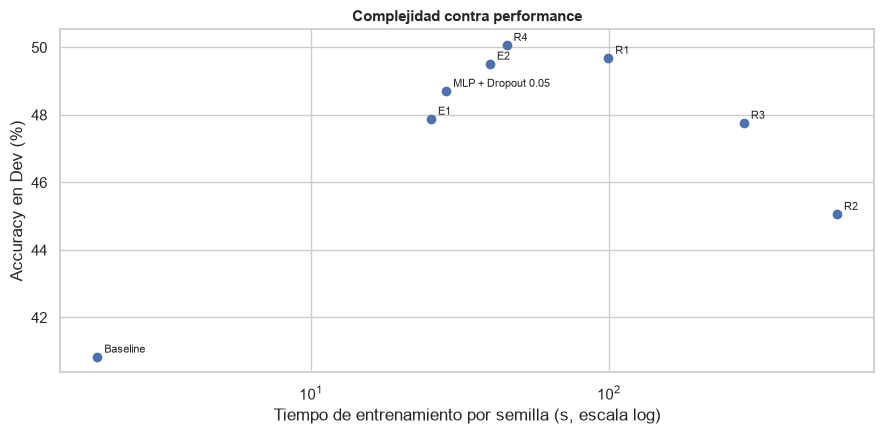

In [6]:
# ==============================================================================
# 3.1 TABLA COMPARATIVA
# ==============================================================================
ARQ = {
    "E1 — Desde cero, 16 dim.":  "Embedding(16) → Dense 128-64-32 → softmax",
    "E2 — Desde cero, 300 dim.": "Embedding(300) → Dense 128-64-32 → softmax",
    "R1 — LSTM, 5 caracteres":   "Embedding(300) → LSTM(128) → softmax, 5 caracteres",
    "R2 — LSTM, 40 caracteres":  "Embedding(300) → LSTM(128) → softmax, 40 caracteres",
    "R3 — LSTM 40 + ES":         "Embedding(300) → LSTM(128) → softmax, 40 caracteres, Early Stopping",
    "R4 — LSTM 5 + ES":          "Embedding(300) → LSTM(128) → softmax, 5 caracteres, Early Stopping",
}
filas = [
    {"Etapa": 1, "Modelo": "Baseline", "Arquitectura": f"One-hot de {ref_base['K']} caracteres → regresión logística",
     "Parámetros": ref_base["parametros_entrenables"], "Dev": f"{ref_base['accuracy_dev']*100:.2f}%",
     "Test": "—", "Tiempo por semilla (s)": ref_base["tiempo_entrenamiento_s"], "Corridas": 1},
    {"Etapa": 2, "Modelo": f"MLP + {reg2['ganador']}", "Arquitectura": "One-hot → Dense 128-64-32 → softmax",
     "Parámetros": ref2["params"], "Dev": f"{ref2['dev_acc_mean']*100:.2f}% ± {ref2['dev_acc_std']*100:.2f}%",
     "Test": "—", "Tiempo por semilla (s)": ref2["tiempo_mean"], "Corridas": 5},
]
for n, r in res3["resultados"].items():
    if n not in ARQ:
        continue  # E0 es el mismo modelo que el ganador de la Etapa 2
    filas.append({"Etapa": 3, "Modelo": n, "Arquitectura": ARQ[n], "Parámetros": r["params"],
                  "Dev": f"{r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}%",
                  "Test": f"{df_test['test_acc'].mean()*100:.2f}% ± {df_test['test_acc'].std()*100:.2f}%" if n == GANADOR else "—",
                  "Tiempo por semilla (s)": r["tiempo_mean"], "Corridas": 5})

tabla_final = pd.DataFrame(filas).set_index("Modelo")
tabla_final["Parámetros"] = tabla_final["Parámetros"].map("{:,}".format)
# Total = tiempo por semilla × cantidad de corridas (el baseline es determinístico y se entrena una vez)
tabla_final["Total con 5 semillas (min)"] = (tabla_final["Tiempo por semilla (s)"] * tabla_final.pop("Corridas") / 60).round(1)
tabla_final["Tiempo por semilla (s)"] = tabla_final["Tiempo por semilla (s)"].round(1)
display(tabla_final)

# Complejidad contra performance: parámetros y tiempo frente a la accuracy en Dev
dev_num = [ref_base["accuracy_dev"], ref2["dev_acc_mean"]] + [res3["resultados"][n]["dev_acc_mean"] for n in tabla_final.index[2:]]
t_num = [ref_base["tiempo_entrenamiento_s"], ref2["tiempo_mean"]] + [res3["resultados"][n]["tiempo_mean"] for n in tabla_final.index[2:]]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(t_num, np.array(dev_num) * 100)
for n, t, a in zip(tabla_final.index, t_num, dev_num):
    ax.annotate(n.split(" — ")[0], (t, a * 100), textcoords="offset points", xytext=(5, 3), fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Tiempo de entrenamiento por semilla (s, escala log)")
ax.set_ylabel("Accuracy en Dev (%)")
ax.set_title("Complejidad contra performance", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

**Trade-off entre complejidad y performance.**
- **El salto más grande es el primero:** del baseline al MLP, los parámetros pasan de 19.908 a 53.536 y la accuracy en Dev sube $7,88$ pp.
- **Después, cada punto cuesta mucho más:** del MLP a R4, los parámetros se multiplican por 4,6 (247.104) y la accuracy sube $1,36$ pp. El tiempo por corrida pasa de 28 a 45 s, gracias a que Early Stopping corta a R4 en unas 47 épocas.
- **El costo real es el total:** la Etapa 3 completa entrena unos 93 minutos, y solo R2 se lleva 49 (583 s por semilla). R4, el ganador, tarda 4 minutos con las 5 semillas.
- **Más complejidad no garantiza más acierto:** R2, el modelo más lento ($583$ s por corrida), es el peor de la Etapa 3. Del otro lado, E1 alcanza $47,88\%$ con 23.840 parámetros, menos de la mitad que el MLP.

---
# 4. Consigna 4.5.3: Análisis ético y de sesgos
### 4.1 Sesgos del texto
El dataset es un solo cuento de 1923, en inglés literario y narrado en primera persona por un hombre. Antes de opinar, medimos en el texto dos cosas que se pueden contar: el **género** de los pronombres y sustantivos de persona, y qué tan **arcaico o raro** es el vocabulario respecto del resto del cuento.

In [7]:
# ==============================================================================
# 4.1 SESGOS MEDIBLES EN EL TEXTO
# ==============================================================================
palabras = re.findall(r"[a-z]+", text.lower())
frec = Counter(palabras)

GENERO = {
    "masculino": ["he", "him", "his", "himself", "man", "men", "father", "fathers", "son", "sons", "brother", "grandfather", "sir"],
    "femenino":  ["she", "her", "hers", "herself", "woman", "women", "mother", "mothers", "daughter", "sister", "grandmother", "lady"],
}
df_gen = pd.DataFrame({g: {"Apariciones": sum(frec[w] for w in ws),
                           "Palabras presentes": ", ".join(f"{w} ({frec[w]})" for w in ws if frec[w])}
                       for g, ws in GENERO.items()}).T
display(df_gen)

n_unicas = len(frec)
hapax = sum(1 for w, n in frec.items() if n == 1)
print(f"Palabras en el texto: {len(palabras):,} | distintas: {n_unicas:,} | aparecen una sola vez: {hapax:,} ({hapax/n_unicas*100:.1f}% del vocabulario)")

,Apariciones,Palabras presentes
masculino,52,"he (18), him (3), his (9), himself (1), man (1..."
femenino,10,"her (2), woman (8)"


Palabras en el texto: 3,621 | distintas: 1,235 | aparecen una sola vez: 858 (69.5% del vocabulario)


**Interpretación.**
- **Género:** las palabras masculinas aparecen 52 veces y las femeninas 10. Del lado femenino solo hay *woman* (8) y *her* (2); *she* no aparece nunca. El narrador es un hombre, y *man* aparece 15 veces, 12 de ellas como *old man*, el anciano que lo guía. *woman* aparece sobre todo como *old woman* (5 de 8).
- **Idioma y época:** es inglés literario de 1923 de un solo autor. El $69,5\%$ de las palabras distintas aparece una sola vez, muchas de ellas arcaicas o propias del estilo de Lovecraft (*eldritch*, *daemonolatreia*). El modelo aprende ese estilo y nada más.
- **Lo que no podemos medir:** etnia o clase social no se reflejan en conteos simples de un cuento de 3.621 palabras. Lo dejamos como limitación, no como ausencia de sesgo.
- **Qué implica para el modelo:** no predice palabras sino caracteres, pero aprende las frecuencias de las secuencias del texto. Si generara texto, reproduciría estas proporciones y este registro.

### 4.2 Desempeño por subgrupos en Test
Medimos la accuracy del ganador en Test (media de las 5 semillas) en dos agrupaciones, y la comparamos con Dev:
1. **Tipo de carácter**, las mismas categorías de las Etapas 2 y 3.
2. **Frecuencia del carácter en Train:** los 10 más frecuentes, los puestos 11 a 30 y el resto. Muestra si el modelo trata peor a las clases poco representadas.

,Casos en Test,Accuracy Dev,Accuracy Test
espacio,443,0.9066,0.8628
vocal,745,0.4193,0.4046
consonante,1231,0.4310,0.3751
mayúscula,48,0.1579,0.1000
puntuación/dígito,53,0.0333,0.0264


,Casos en Test,Accuracy Dev,Accuracy Test
top 10,1817,0.5782,0.5334
puestos 11-30,670,0.3091,0.2710
puesto 31 o más,33,0.0952,0.0242


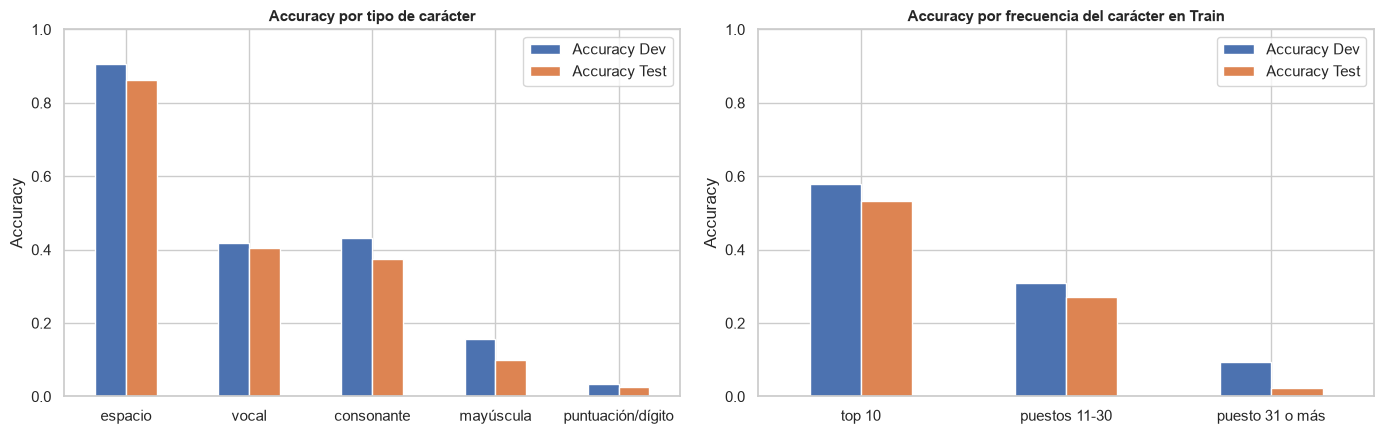

In [8]:
# ==============================================================================
# 4.2 ACCURACY POR SUBGRUPO EN TEST Y EN DEV
# ==============================================================================
def tipo_caracter(c):
    if c == " ":
        return "espacio"
    if c.isupper():
        return "mayúscula"
    if c in "aeiou":
        return "vocal"
    if c.isalpha():
        return "consonante"
    return "puntuación/dígito"

ranking = [c for c, _ in Counter(y_train).most_common()]
def grupo_frecuencia(c):
    p = ranking.index(c) if c in ranking else len(ranking)
    return "top 10" if p < 10 else ("puestos 11-30" if p < 30 else "puesto 31 o más")

def por_subgrupo(funcion, orden):
    g_dev = np.array([funcion(c) for c in y_dev])
    g_test = np.array([funcion(c) for c in y_test])
    return pd.DataFrame({"Casos en Test": [int((g_test == g).sum()) for g in orden],
                         "Accuracy Dev": [aciertos_dev[:, g_dev == g].mean() for g in orden],
                         "Accuracy Test": [aciertos_test[:, g_test == g].mean() for g in orden]}, index=orden).round(4)

df_tipo = por_subgrupo(tipo_caracter, ["espacio", "vocal", "consonante", "mayúscula", "puntuación/dígito"])
df_frec = por_subgrupo(grupo_frecuencia, ["top 10", "puestos 11-30", "puesto 31 o más"])
display(df_tipo)
display(df_frec)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df_tipo[["Accuracy Dev", "Accuracy Test"]].plot.bar(ax=axes[0], rot=0)
df_frec[["Accuracy Dev", "Accuracy Test"]].plot.bar(ax=axes[1], rot=0)
axes[0].set_title("Accuracy por tipo de carácter", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy por frecuencia del carácter en Train", fontsize=11, fontweight="bold")
for ax in axes:
    ax.set_ylim(0, 1)
    ax.set_ylabel("Accuracy")
plt.tight_layout()
plt.show()

**Interpretación.**
- **El modelo no rinde igual para todos los caracteres.** En Test acierta el $86,28\%$ de los espacios, alrededor del $40\%$ de las letras minúsculas, el $10,00\%$ de las mayúsculas y el $2,64\%$ de la puntuación. El orden es el mismo que en Dev.
- **La caída de Dev a Test no es pareja:** las consonantes pierden $5,59$ pp y el espacio $4,38$ pp, mientras que las vocales pierden $1,47$ pp. En mayúsculas y puntuación hay 48 y 53 casos, así que sus diferencias son de pocos aciertos.
- **Por frecuencia, la brecha es enorme:** acierta el $53,34\%$ de los 10 caracteres más frecuentes, el $27,10\%$ de los puestos 11 a 30 y el $2,42\%$ del resto (33 casos). Es el desbalance que vimos en la Etapa 1: el modelo aprende bien lo que aparece mucho en Train.
- **Los subgrupos peor servidos son los que más significado cargan:** las mayúsculas marcan nombres propios e inicios de oración, y la puntuación, la estructura del texto.

### 4.3 Riesgos en un sistema real y mitigación
Un modelo así se usaría para autocompletar o generar texto. Los riesgos que muestran nuestros resultados:
1. **Fuera de su dominio rinde peor.** Aprendió el inglés de un solo cuento de 1923; con texto actual, otro idioma u otro registro, el *data mismatch* bajaría la accuracy. Entre Dev y Test, que son partes del mismo cuento, ya cae $4,37$ pp.
2. **Reproduce el sesgo del texto.** Con 52 menciones masculinas contra 10 femeninas, al generar texto tendería a continuar en masculino y en el registro de Lovecraft.
3. **Falla justo en lo más sensible:** nombres propios (mayúsculas) y puntuación, que es donde un error cambia el sentido de una frase.

**Mitigación:**
- Entrenar con un corpus más grande y variado, y documentar de dónde sale (autores, épocas, registro).
- Medir el desempeño por subgrupo antes de usarlo, como en la sección 4.2, y no aplicarlo a otro dominio sin volver a evaluarlo.
- Si genera texto, revisión humana y un aviso claro de que imita el estilo de un autor de 1923.

---
# 5. Consigna 4.5.4: Conclusiones

### Aprendizajes más importantes
1. **La partición decide si los números valen.** Las ventanas con stride 1 se solapan en 39 caracteres; sin la partición por bloques, Dev y Test hubieran compartido texto con Train.
2. **La mayor mejora vino primero:** del baseline al MLP, $+7,88$ pp en Dev. Embeddings y LSTM sumaron $+1,36$ pp más.
3. **Cuándo parar importa tanto como la arquitectura.** R4 es la misma LSTM que R1 cortada a tiempo: igual accuracy, mucho mejor perplejidad y la mitad del tiempo.
4. **Con pocos datos, el contexto largo no se aprovecha:** la LSTM de 40 caracteres quedó siempre por debajo de la de 5.
5. **Lo pre-entrenado ayuda cuando la unidad tiene significado:** GloVe mejoró la predicción de palabras.
6. **Test confirma que el modelo generaliza, pero menos de lo que decía Dev:** $45,70\%$ contra $50,07\%$.
7. **El límite son los datos:** sumar un segundo cuento a Train sube R4 $4,09$ pp en Dev, más que cualquier cambio de arquitectura.

### Lo más desafiante y cómo se resolvió
- **Diferencias del tamaño del ruido.** Muchas mejoras eran de décimas de punto. Lo resolvimos con 5 semillas por modelo y media ± desvío, y comparando cada mejora con el desvío.
- **Tiempo de entrenamiento sin GPU.** La LSTM de 40 caracteres tardaba casi 10 minutos por semilla. Lo resolvimos con Early Stopping y guardando los resultados de R2 para no reentrenarlo.
- **Unificar el trabajo del grupo.** En paralelo probamos otra partición y otra métrica, y una versión con más cuentos. El notebook final usa una sola partición para que todas las cifras sean comparables, y la idea de más cuentos se midió sobre ella como experimento.

### Limitaciones y qué haríamos diferente
- **Un solo cuento**, de unos 20.000 caracteres: es la limitación principal, como muestra el experimento con *The Call of Cthulhu*.
- **Dev de 8 bloques:** la brecha con Test muestra que no estima con precisión. Con más tiempo, usaríamos validación cruzada por bloques.
- **Test solo para el ganador:** no sabemos si el orden entre los modelos se mantiene fuera de Dev.
- **Con más tiempo:** rehacer las Etapas 2 y 3 con varios cuentos en Train y graficar la curva de aprendizaje; probar la LSTM de 40 caracteres con más datos y GPU; y hacer la Etapa 4 (optativa), por ejemplo un VAE sobre ventanas de caracteres.

In [9]:
# ==============================================================================
# 5.1 PERSISTENCIA DE LOS RESULTADOS DE LA ETAPA 5
# ==============================================================================
with open(PROC / "resultados_etapa5.json", "w", encoding="utf-8") as f:
    json.dump({"ganador": GANADOR, "config": CFG_GANADOR, "corridas": corridas,
               "dev_acc_mean": float(df_test["dev_acc"].mean()), "test_acc_mean": float(df_test["test_acc"].mean()),
               "test_acc_std": float(df_test["test_acc"].std()),
               "subgrupos": {"tipo": df_tipo.to_dict(), "frecuencia": df_frec.to_dict()}},
              f, indent=2, ensure_ascii=False, default=float)
print("Resultados guardados en data/processed/resultados_etapa5.json")

Resultados guardados en data/processed/resultados_etapa5.json
